In [29]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict

In [30]:
class MarkStatus(TypedDict):
    marks: int
    status = str

In [31]:
def passing_marks(state: MarkStatus):
    print("you are  are pass, congratulation")
    return {'status': 'pass'}

In [32]:
def fail(state: MarkStatus):
    print("sorry try again")
    return {'status': 'fail'}

In [33]:
def check_marks(state: MarkStatus):
    if state['marks'] >= 40:
        return 'pass'
    return 'fail'


In [ ]:
graph = StateGraph(MarkStatus)
# adding node
graph.add_node('pass',passing_marks)
graph.add_node('fail',fail)

# edge
graph.add_conditional_edges(
    START,
    check_marks,{
        'pass':'pass', # if condition give pass then it go to pass node
        'fail':'fail' # if condition give fail then it go to fail node
    }
)
graph.add_edge('pass', END)
graph.add_edge('fail', END)

workflow = graph.compile()

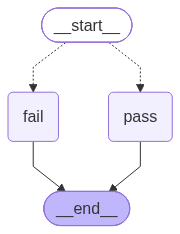

In [35]:
workflow

In [37]:
marks = {
    'marks': 40,
}
result = workflow.invoke(marks)
print(result)

you are  are pass, congratulation
{'marks': 40}
